# 06 — Emerging Hot Spot Analysis from esda Gi* + pymannkendall

**Method.** Emerging Hot Spot Analysis (EHSA) as documented by Esri, *How Emerging Hot Spot Analysis works*
(ArcGIS Pro, <https://pro.arcgis.com/en/pro-app/latest/tool-reference/space-time-pattern-mining/learnmoreemerging.htm>,
which now redirects to `doc.esri.com/en/arcgis-pro/latest/...`; fetched 2026-10-31):

1. a Getis–Ord Gi* z-score for every space-time bin (unit × quarter), computed over the bin's
   **space-time neighbourhood** (its spatial neighbours in the same bin and, with a neighbourhood time step of 1,
   the same locations one time step earlier — "temporal neighbors are backward in time only");
2. a Mann–Kendall trend test on each unit's series of Gi* z-scores;
3. Esri's rule table, which combines the per-bin significance pattern and the trend into one of
   8 hot + 8 cold categories or *no pattern detected*.

**Libraries (called directly; versions printed below).**
`libpysal` (queen contiguity; the space-time weights are built from its sparse matrix and turned back into a
`libpysal.weights.W`), `esda.G_Local(star=True)` (Gi*, analytic z), `pymannkendall.original_test`
(Mann–Kendall; `hamed_rao_modification_test` as a sensitivity), `statsmodels.stats.multitest.multipletests`
(Benjamini–Hochberg). Esri's category rules are written out below as plain Python.

**Citations.** Getis, A. & Ord, J.K. (1992). The analysis of spatial association by use of distance
statistics. *Geographical Analysis* 24(3). Ord, J.K. & Getis, A. (1995). Local spatial autocorrelation
statistics: distributional issues and an application. *Geographical Analysis* 27(4). Mann, H.B. (1945).
Nonparametric tests against trend. *Econometrica* 13. Kendall, M.G. (1975). *Rank Correlation Methods*.
Griffin. Hamed, K.H. & Rao, A.R. (1998). A modified Mann-Kendall trend test for autocorrelated data.
*Journal of Hydrology* 204. Benjamini, Y. & Hochberg, Y. (1995). *JRSS B* 57(1). Rey, S.J. & Anselin, L.
(2007). PySAL: A Python library of spatial analytical methods. *Review of Regional Studies* 37(1).
Hussain, M. & Mahmud, I. (2019). pyMannKendall: a python package for non parametric Mann Kendall family of
trend tests. *Journal of Open Source Software* 4(39).

**Primary configuration.** Every spatial crime group on the 2,592 census tracts; 16 quarterly bins
2022Q1–2025Q4 (`Warehouse.counts(CrimeQuery(crime_group=g, time_unit="quarter"))`); queen contiguity,
binary weights; neighbourhood time step k = 1; analytic two-sided p; α = 0.05 for the bins and for the
trend (project choice — the Esri page does not state the level); no multiple-testing correction in the
primary labels, Benjamini–Hochberg (BH) labels reported alongside. Sensitivities: BH; α = 0.01; purely spatial neighbourhood (no temporal neighbours);
Hamed–Rao Mann–Kendall (where its corrected variance comes out negative, pymannkendall returns p = NaN
and the unit is treated as having no significant trend; the count is reported); monthly bins (48).

In [1]:
import time
import warnings
from importlib.metadata import version

import esda
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
import scipy.sparse as sp
from scipy import stats
from statsmodels.stats.multitest import multipletests

from crime.core.config import NOTEBOOK_OUTPUTS_DIR
from crime.data import CrimeQuery, Warehouse

import _mapstyle as ms  # notebooks/_mapstyle.py: basemap, overlay, graticule, scale bar, legends

warnings.filterwarnings("ignore", category=FutureWarning)
OUT = NOTEBOOK_OUTPUTS_DIR / "06_ehsa"
OUT.mkdir(parents=True, exist_ok=True)
ms.setup()

GROUPS = ("all", "property", "bodily_harm", "traffic", "drug", "violent")
SUPPORTS = ("tract",)
K_TIME = 1            # neighbourhood time step (Esri default 1)
ALPHA = 0.05          # bin and trend significance (project choice)
FRAC = 0.9            # Esri's "90 percent of the time-step intervals"
TIME_UNIT = {"Q": "quarter", "M": "month"}

wh = Warehouse()


def tract_cube(group, freq):
    """Space-time cube of one group: rows = tracts (tract-id order), columns = bin starts, zero-filled.

    The warehouse returns one row per tract and bin (long format); the pivot turns it into the
    unit x bin matrix the Gi* and Mann-Kendall code below works on. unit_id is the census tract id.
    """
    c = wh.counts(CrimeQuery(crime_group=group, time_unit=TIME_UNIT[freq]))
    Y = c.pivot(index="census_tract_id", columns="period_start", values="count")
    Y.index.name, Y.columns.name = "unit_id", "period"
    return Y

for pkg in ("libpysal", "esda", "pymannkendall", "statsmodels", "geopandas", "numpy", "scipy"):
    print(f"{pkg:14s} {version(pkg)}")

libpysal       4.12.1
esda           2.6.0
pymannkendall  1.4.3
statsmodels    0.15.0
geopandas      1.1.3
numpy          2.3.5
scipy          1.16.3


## 1. Space-time cube and space-time neighbourhood

The cube is `tract_cube(group, freq)`: one row per tract, one column per bin, zero-filled.
Bin (i, t) is node `t·n + i` of a graph with n·T nodes. With the spatial binary queen matrix **A**
(n × n), the identity **I**, and the T × T lag matrix **L** (L[t, t−1] = 1), the space-time
adjacency is

$$W_{st} = I_T \otimes A \;+\; L \otimes (A + I_n),$$

i.e. bin (i, t) has as neighbours the queen neighbours of i at t, the queen neighbours of i at t−1 and
i itself at t−1. `G_Local(star=True)` with `transform="B"` adds the bin itself with weight 1, so every
member of the neighbourhood has weight 1 (binary weights; for these esda's analytic variance is the exact
Getis–Ord one — see `docs/METHODS.md` §2b). Bins of the first quarter have no temporal neighbours.

**Global moments.** One `G_Local` call on the whole cube uses the mean and variance of **all** n·T bins as
the reference. That is the textbook Gi* applied to the cube's bins; the Esri page does not say which
reference it uses.
The **purely spatial** variant runs `G_Local` separately on each quarter with the queen weights (reference =
that quarter); it is an exact library call too, but it is *not* Esri's neighbourhood (no temporal neighbours).

In [2]:
def space_time_weights(w_spatial, n_times, k=K_TIME):
    # Space-time W (node t*n+i): queen nbrs at t; queen nbrs and self at t-1..t-k. Binary.
    A = w_spatial.sparse.copy().tocsr()
    A.data[:] = 1.0
    n = A.shape[0]
    I_n = sp.identity(n, format="csr")
    Wst = sp.kron(sp.identity(n_times), A)
    for lag in range(1, k + 1):
        L = sp.eye(n_times, k=-lag, format="csr")     # L[t, t-lag] = 1
        Wst = Wst + sp.kron(L, A + I_n)
    Wst = sp.csr_matrix(Wst)
    return libpysal.weights.WSP(Wst).to_W(silence_warnings=True)


data = {}
for s in SUPPORTS:
    units = wh.census_tracts().rename(columns={"census_tract_id": "unit_id"})
    w = libpysal.weights.Queen.from_dataframe(units, ids="unit_id", use_index=False)
    w.transform = "B"
    assert list(w.id_order) == list(units.unit_id)
    data[s] = dict(units=units, w=w)
    print(f"{s}: {w.n} units, mean queen neighbours {w.mean_neighbors:.2f}, islands {len(w.islands)}")

# check the construction on one tract
s = "tract"; n = data[s]["w"].n
wst = space_time_weights(data[s]["w"], 16)
i, t = 100, 5
nb = np.array(wst.neighbors[t * n + i])
queen = set(data[s]["w"].sparse[i].indices)
same_t = {j % n for j in nb if j // n == t}
prev_t = {j % n for j in nb if j // n == t - 1}
print("tract", i, "quarter", t, ": neighbours at t =", len(same_t), "(queen", len(queen), "); at t-1 =",
      len(prev_t), "(queen + self", len(queen | {i}), "); other quarters:", sum(j // n not in (t, t - 1) for j in nb))
assert same_t == queen and prev_t == queen | {i}
del wst

tract: 2592 units, mean queen neighbours 6.03, islands 0
tract 100 quarter 5 : neighbours at t = 13 (queen 13 ); at t-1 = 14 (queen + self 14 ); other quarters: 0


## 2. Gi* per bin and Mann–Kendall per unit

* **Gi\***: `esda.G_Local(y, W_st, transform="B", star=True, permutations=0)` → `Zs` (analytic z).
  Two-sided p = 2·Φ(−|z|) (esda's `p_norm` is one-sided; `docs/METHODS.md` §2b). A bin is a
  significant **hot** bin if p < α and z > 0, **cold** if p < α and z < 0. BH: one family per run
  (all n·T bins), project choice.
* **Mann–Kendall**: `pymannkendall.original_test(z_i, alpha)` on the 16 z-scores of unit i
  (S statistic, tie-corrected variance, continuity-corrected normal p). The Esri page says the trend
  test is applied to "these hot and cold spot trends" and returns a trend z and p per location; testing the
  Gi* z series follows Esri's description.

In [3]:
def gi_star_cube(Y, w, k=K_TIME, spatial_only=False):
    # Return z, p (two-sided) as (n_units, n_times) arrays.
    n, T = Y.shape
    if spatial_only:
        Z = np.column_stack([
            esda.G_Local(Y[:, t].astype(float), w, transform="B", star=True, permutations=0).Zs
            for t in range(T)])
    else:
        wst = space_time_weights(w, T, k)
        y = Y.T.reshape(-1).astype(float)          # node t*n+i
        g = esda.G_Local(y, wst, transform="B", star=True, permutations=0)
        Z = g.Zs.reshape(T, n).T
    P = 2 * stats.norm.sf(np.abs(Z))
    return Z, P


def mann_kendall(Z, alpha=ALPHA, hamed_rao=False):
    f = mk.hamed_rao_modification_test if hamed_rao else mk.original_test
    rows = [f(z, alpha=alpha) for z in Z]
    return pd.DataFrame({"mk_s": [r.s for r in rows], "mk_tau": [r.Tau for r in rows],
                         "mk_z": [r.z for r in rows], "mk_p": [r.p for r in rows]})

## 3. Esri's category rules

Esri's definitions, verbatim from the page cited above (hot spots; the cold-spot rows are the same with
hot ↔ cold, and "intensifying" / "diminishing" refer to the intensity of clustering of **low** counts):

| Pattern | Esri definition |
|---|---|
| No Pattern Detected | Does not fall into any of the hot or cold spot patterns defined below. |
| New Hot Spot | A location that is a statistically significant hot spot for the final time step and has never been a statistically significant hot spot before. |
| Consecutive Hot Spot | A location with a single uninterrupted run of at least two statistically significant hot spot bins in the final time-step intervals. The location has never been a statistically significant hot spot prior to the final hot spot run and less than 90 percent of all bins are statistically significant hot spots. |
| Intensifying Hot Spot | A location that has been a statistically significant hot spot for 90 percent of the time-step intervals, including the final time step. In addition, the intensity of clustering of high counts in each time step is increasing overall and that increase is statistically significant. |
| Persistent Hot Spot | A location that has been a statistically significant hot spot for 90 percent of the time-step intervals with no discernible trend in the intensity of clustering over time. |
| Diminishing Hot Spot | A location that has been a statistically significant hot spot for 90 percent of the time-step intervals, including the final time step. In addition, the intensity of clustering in each time step is decreasing overall and that decrease is statistically significant. |
| Sporadic Hot Spot | A statistically significant hot spot for the final time-step interval with a history of also being an on-again and off-again hot spot. Less than 90 percent of the time-step intervals have been statistically significant hot spots and none of the time-step intervals have been statistically significant cold spots. |
| Oscillating Hot Spot | A statistically significant hot spot for the final time-step interval that has a history of also being a statistically significant cold spot during a prior time step. Less than 90 percent of the time-step intervals have been statistically significant hot spots. |
| Historical Hot Spot | The most recent time period is not hot, but at least 90 percent of the time-step intervals have been statistically significant hot spots. |

**How the text is turned into code (project choices where Esri is silent or two rows overlap).**
With T = 16, "90 percent" means at least 0.9·16 = 14.4, i.e. **≥ 15 significant bins**. "Increasing
intensity" for hot spots = Mann–Kendall S > 0 with p < α on the z series; for cold spots, increasing
intensity of low-count clustering = S < 0 with p < α. Precedence, evaluated for the hot side and then
the cold side:

1. ≥ 90 % of bins of this side: final bin not of this side → **historical**; else significant trend in
   the intensifying direction → **intensifying**; significant trend in the other direction →
   **diminishing**; no significant trend → **persistent**.
2. Otherwise, final bin significant of this side: any significant bin of the opposite side earlier →
   **oscillating** (it would also satisfy "new" / "consecutive", which only forbid earlier bins of the
   *same* side; oscillating is the more specific row); exactly one bin of this side → **new**; the bins of
   this side form one run of ≥ 2 that ends in the final bin → **consecutive**; otherwise → **sporadic**.
3. Otherwise **no pattern detected**. In particular a unit with hot bins in the past but **not in the final
   bin** and fewer than 90 % hot bins is *no pattern* under the current Esri text, because Esri's sporadic
   row requires a significant final bin.

In [4]:
CATEGORIES = [f"{p} {side} spot" for side in ("hot", "cold")
              for p in ("new", "consecutive", "intensifying", "persistent",
                        "diminishing", "sporadic", "oscillating", "historical")] + ["no pattern detected"]


def esri_category(hot, cold, mk_s, mk_p, alpha=ALPHA, frac=FRAC):
    # hot, cold: boolean arrays over the T bins (significant hot / cold bins) of one unit
    T = len(hot)
    trend_up = (mk_p < alpha) and (mk_s > 0)      # Gi* z rising
    trend_dn = (mk_p < alpha) and (mk_s < 0)      # Gi* z falling
    sides = (("hot", hot, cold, trend_up, trend_dn),     # (name, this side, other side,
             ("cold", cold, hot, trend_dn, trend_up))    #  intensifying, diminishing)
    # rule 1: >= 90 % of the bins on one side
    for name, this, other, intens, dimin in sides:
        if this.sum() >= frac * T:
            if not this[-1]:
                return f"historical {name} spot"
            if intens:
                return f"intensifying {name} spot"
            if dimin:
                return f"diminishing {name} spot"
            return f"persistent {name} spot"
    # rule 2: significant final bin, < 90 % of the bins on that side
    for name, this, other, intens, dimin in sides:
        if this[-1]:
            if other[:-1].any():
                return f"oscillating {name} spot"
            n_this = int(this.sum())
            if n_this == 1:
                return f"new {name} spot"
            run = len(this) - np.flatnonzero(~this)[-1] - 1 if (~this).any() else len(this)
            if run >= 2 and run == n_this:
                return f"consecutive {name} spot"
            return f"sporadic {name} spot"
    return "no pattern detected"


# unit checks on hand-made sequences (T = 16)
F, Tr = False, True
def seq(idx, T=16):
    a = np.zeros(T, bool); a[list(idx)] = True; return a
none = seq([])
assert esri_category(seq([15]), none, 0, 1) == "new hot spot"
assert esri_category(seq([13, 14, 15]), none, 0, 1) == "consecutive hot spot"
assert esri_category(seq([2, 14, 15]), none, 0, 1) == "sporadic hot spot"
assert esri_category(seq([2, 15]), none, 0, 1) == "sporadic hot spot"
assert esri_category(seq([2, 5]), none, 0, 1) == "no pattern detected"          # not hot at the end
assert esri_category(seq([15]), seq([3]), 0, 1) == "oscillating hot spot"
assert esri_category(seq(range(1, 16)), none, 50, 0.001) == "intensifying hot spot"
assert esri_category(seq(range(1, 16)), none, -50, 0.001) == "diminishing hot spot"
assert esri_category(seq(range(1, 16)), none, 3, 0.6) == "persistent hot spot"
assert esri_category(seq(range(0, 15)), none, 3, 0.6) == "historical hot spot"
assert esri_category(none, seq(range(16)), -50, 0.001) == "intensifying cold spot"
assert esri_category(none, seq(range(16)), 50, 0.001) == "diminishing cold spot"
assert esri_category(none, seq([14, 15]), 0, 1) == "consecutive cold spot"
print("rule checks passed;", len(CATEGORIES), "categories")

rule checks passed; 17 categories


## 4. Run every configuration

Primary: quarterly, space-time neighbourhood, raw two-sided p < 0.05, `original_test`. For each run the
labels under the sensitivities are added as extra columns. The monthly runs (48 bins; 90 % = 44 bins)
repeat the primary settings.

In [5]:
def classify(Z, P, mkdf, alpha=ALPHA):
    hot = (P < alpha) & (Z > 0)
    cold = (P < alpha) & (Z < 0)
    return [esri_category(hot[i], cold[i], mkdf.mk_s[i], mkdf.mk_p[i], alpha) for i in range(len(Z))], hot, cold


labels, bins, runtimes = {}, [], []
for freq in ("Q", "M"):
    for s in SUPPORTS:
        for g in GROUPS:
            t0 = time.time()
            Y = tract_cube(g, freq)
            assert list(Y.index) == list(data[s]["units"].unit_id)
            periods = list(Y.columns)
            Yv = Y.to_numpy()
            w = data[s]["w"]
            Z, P = gi_star_cube(Yv, w)
            m = mann_kendall(Z)
            cat, hot, cold = classify(Z, P, m)
            df = pd.DataFrame({"unit_id": Y.index, "category": cat,
                               "n_hot_bins": hot.sum(1), "n_cold_bins": cold.sum(1)}).join(m)
            # BH over all bins of this run
            P_bh = multipletests(P.ravel(), method="fdr_bh")[1].reshape(P.shape)
            df["category_fdr"], *_ = classify(Z, P_bh, m)
            if freq == "Q":
                m01 = mann_kendall(Z, alpha=0.01)
                df["category_a01"], *_ = classify(Z, P, m01, alpha=0.01)
                with np.errstate(invalid="ignore"):
                    m_hr = mann_kendall(Z, hamed_rao=True)
                df["mk_p_hamed_rao"] = m_hr.mk_p
                # pymannkendall's Hamed-Rao variance correction can be negative -> p = NaN;
                # such units are treated as "no significant trend"
                df["category_hamed_rao"], *_ = classify(Z, P, m_hr)
                Zs, Ps = gi_star_cube(Yv, w, spatial_only=True)
                m_sp = mann_kendall(Zs)
                df["category_spatial"], *_ = classify(Zs, Ps, m_sp)
                long = pd.DataFrame({"unit_id": np.repeat(Y.index.values, len(periods)),
                                     "period": np.tile(periods, len(Y)),
                                     "z": Z.ravel(), "p": P.ravel(), "p_bh": P_bh.ravel(),
                                     "z_spatial": Zs.ravel(), "p_spatial": Ps.ravel()})
                long.insert(0, "group", g); long.insert(0, "support", s)
                bins.append(long)
            labels[(freq, s, g)] = df
            runtimes.append(dict(freq=freq, support=s, group=g, n_units=len(Y), n_bins=Yv.size,
                                 seconds=round(time.time() - t0, 1)))
runtimes = pd.DataFrame(runtimes)
runtimes

,freq,support,group,n_units,n_bins,seconds
0,Q,tract,all,2592,41472,6.5
1,Q,tract,property,2592,41472,6.6
2,Q,tract,bodily_harm,2592,41472,6.3
3,Q,tract,traffic,2592,41472,6.3
4,Q,tract,drug,2592,41472,6.2
5,Q,tract,violent,2592,41472,6.3
6,M,tract,all,2592,124416,4.4
7,M,tract,property,2592,124416,4.5
8,M,tract,bodily_harm,2592,124416,4.3
9,M,tract,traffic,2592,124416,4.2


In [6]:
def counts_table(key_cols, col="category"):
    rows = {}
    for key, df in labels.items():
        if col in df:
            rows[key] = df[col].value_counts()
    t = pd.DataFrame(rows).reindex(CATEGORIES).fillna(0).astype(int)
    t.columns = [f"{f}/{s}/{g}" for f, s, g in t.columns]
    t = t.loc[(t.sum(1) > 0) | (t.index == "no pattern detected")]
    return t

print("Units per category — primary (raw p < 0.05, space-time neighbourhood, original MK)")
primary_counts = counts_table(None)
primary_counts

Units per category — primary (raw p < 0.05, space-time neighbourhood, original MK)


,Q/tract/all,Q/tract/property,Q/tract/bodily_harm,Q/tract/traffic,Q/tract/drug,Q/tract/violent,M/tract/all,M/tract/property,M/tract/bodily_harm,M/tract/traffic,M/tract/drug,M/tract/violent
category,,,,,,,,,,,,
new hot spot,3,4,58,14,18,20,15,13,27,5,4,16
consecutive hot spot,18,14,43,38,42,45,0,0,10,0,13,4
intensifying hot spot,37,29,10,6,16,0,30,26,4,1,3,0
persistent hot spot,136,133,29,77,12,0,73,60,3,8,8,0
diminishing hot spot,27,34,0,0,0,0,45,58,0,0,1,0
sporadic hot spot,68,61,233,294,109,219,86,82,247,250,160,198
oscillating hot spot,0,0,0,0,0,0,1,1,0,0,0,0
historical hot spot,5,10,0,2,0,0,7,10,0,18,0,0
consecutive cold spot,0,1,0,0,0,0,0,0,0,0,0,0


In [7]:
variant_rows = []
for (f, s, g), df in labels.items():
    if f != "Q":
        continue
    for col in ["category", "category_fdr", "category_a01", "category_hamed_rao", "category_spatial"]:
        c = df[col]
        variant_rows.append(dict(support=s, group=g, labels=col,
                                 hot=int(c.str.contains("hot").sum()),
                                 cold=int(c.str.contains("cold").sum()),
                                 no_pattern=int((c == "no pattern detected").sum()),
                                 agree_with_primary=round((c == df["category"]).mean(), 3),
                                 hamed_rao_nan_p=int(df["mk_p_hamed_rao"].isna().sum()) if col == "category_hamed_rao" else None))
for (f, s, g), df in labels.items():
    if f == "M":
        c = df["category"]; q = labels[("Q", s, g)]["category"]
        variant_rows.append(dict(support=s, group=g, labels="category (monthly, 48 bins)",
                                 hot=int(c.str.contains("hot").sum()), cold=int(c.str.contains("cold").sum()),
                                 no_pattern=int((c == "no pattern detected").sum()),
                                 agree_with_primary=round((c.values == q.values).mean(), 3)))
variants = pd.DataFrame(variant_rows)
variants.to_csv(OUT / "variants_summary.csv", index=False)
variants

,support,group,labels,hot,cold,no_pattern,agree_with_primary,hamed_rao_nan_p
0,tract,all,category,294,6,2292,1.000,NaN
1,tract,all,category_fdr,170,0,2422,0.937,NaN
2,tract,all,category_a01,205,0,2387,0.941,NaN
3,tract,all,category_hamed_rao,294,6,2292,0.990,45.0
4,tract,all,category_spatial,266,0,2326,0.933,NaN
5,tract,property,category,285,5,2302,1.000,NaN
6,tract,property,category_fdr,165,0,2427,0.941,NaN
7,tract,property,category_a01,199,0,2393,0.940,NaN
8,tract,property,category_hamed_rao,285,5,2302,0.991,45.0
9,tract,property,category_spatial,280,0,2312,0.935,NaN


## 5. Before and after the FDR correction (maps and counts)

Every map draws every unit; *no pattern detected* is light grey. **Left: before FDR** — a bin is significant
if its two-sided Gi* p < 0.05 (the primary labels). **Right: after FDR** — Benjamini–Hochberg over all n·T
bins of the run, a bin is significant if its BH-adjusted q < 0.05 (`category_fdr`). The Mann–Kendall trend
p is not adjusted in either panel (it only splits the ≥ 90 % units into intensifying / persistent /
diminishing). Colour family = hot (reds) or cold (blues); hatch pattern = Esri pattern type; the legend
gives the number of units before → after FDR.
Basemap: Esri World Light Gray Canvas (via contextily).

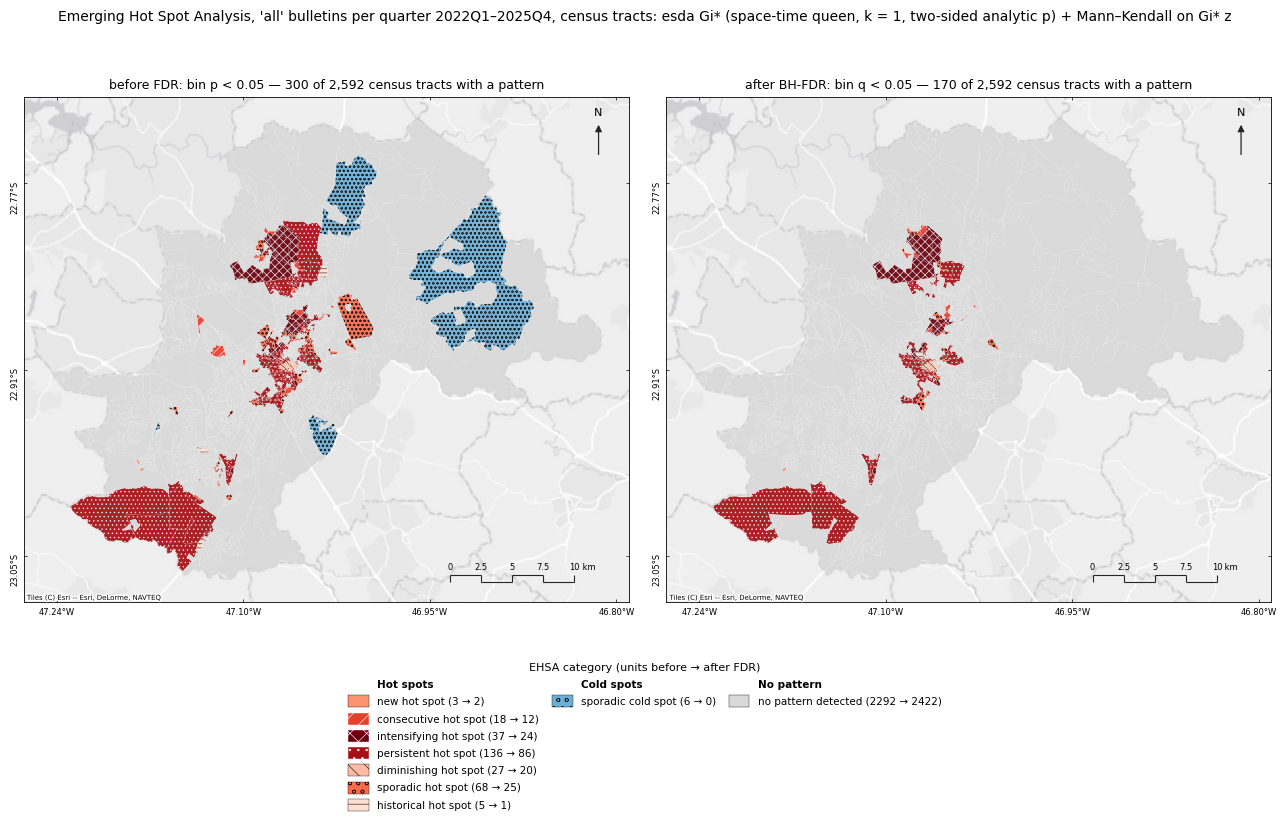

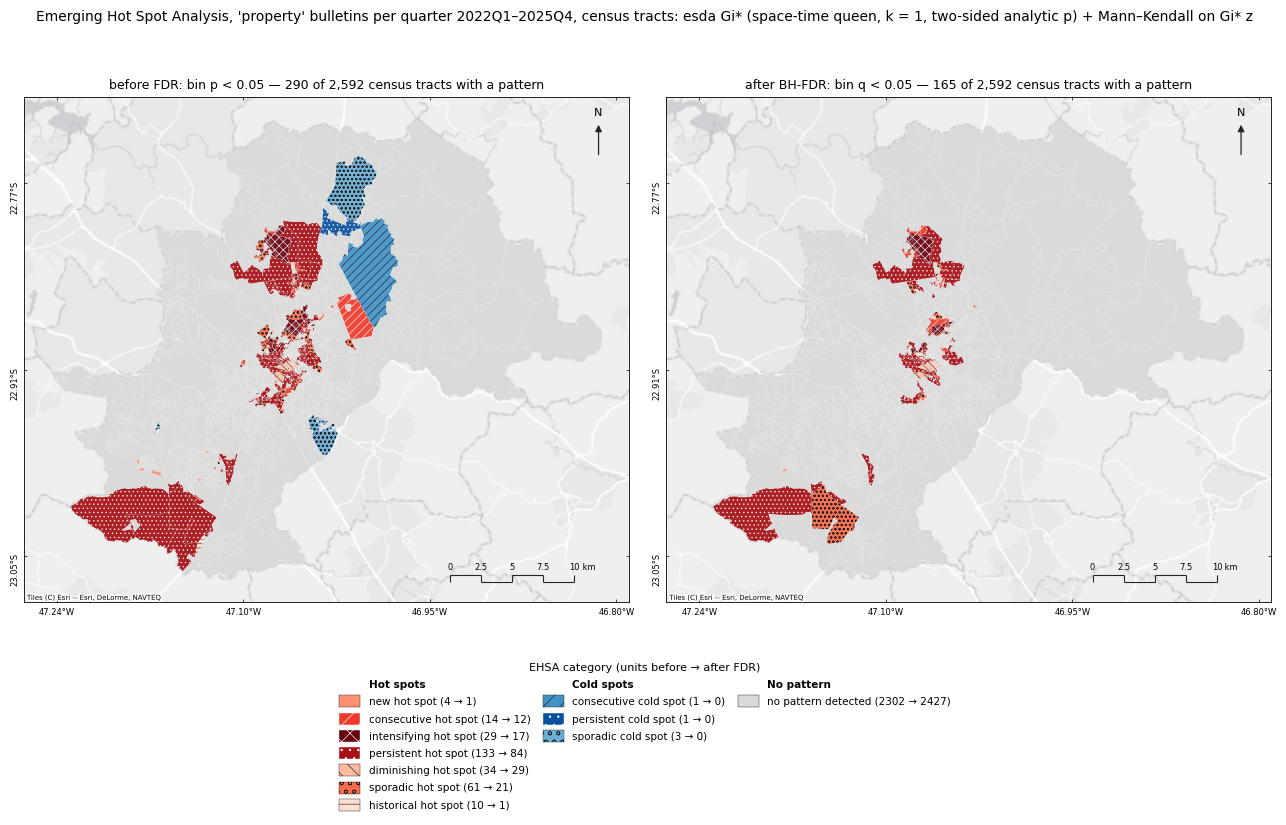

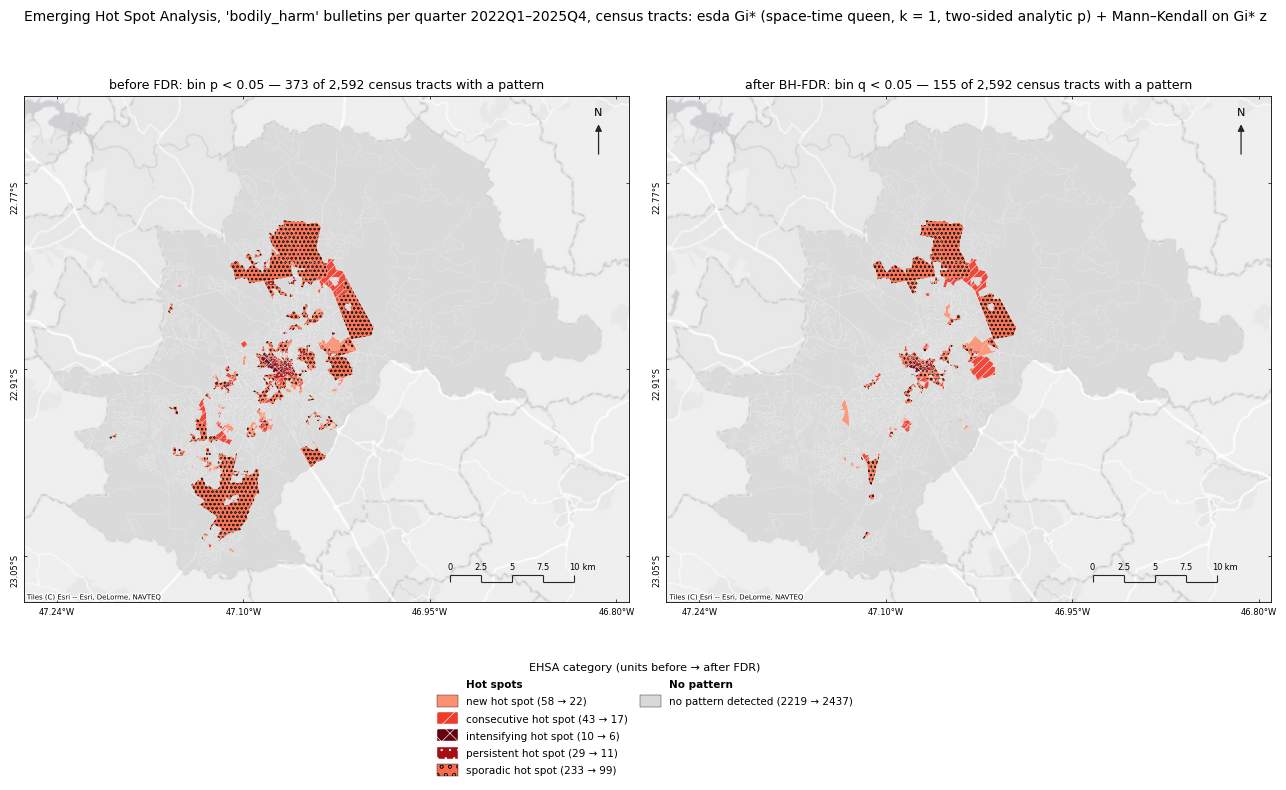

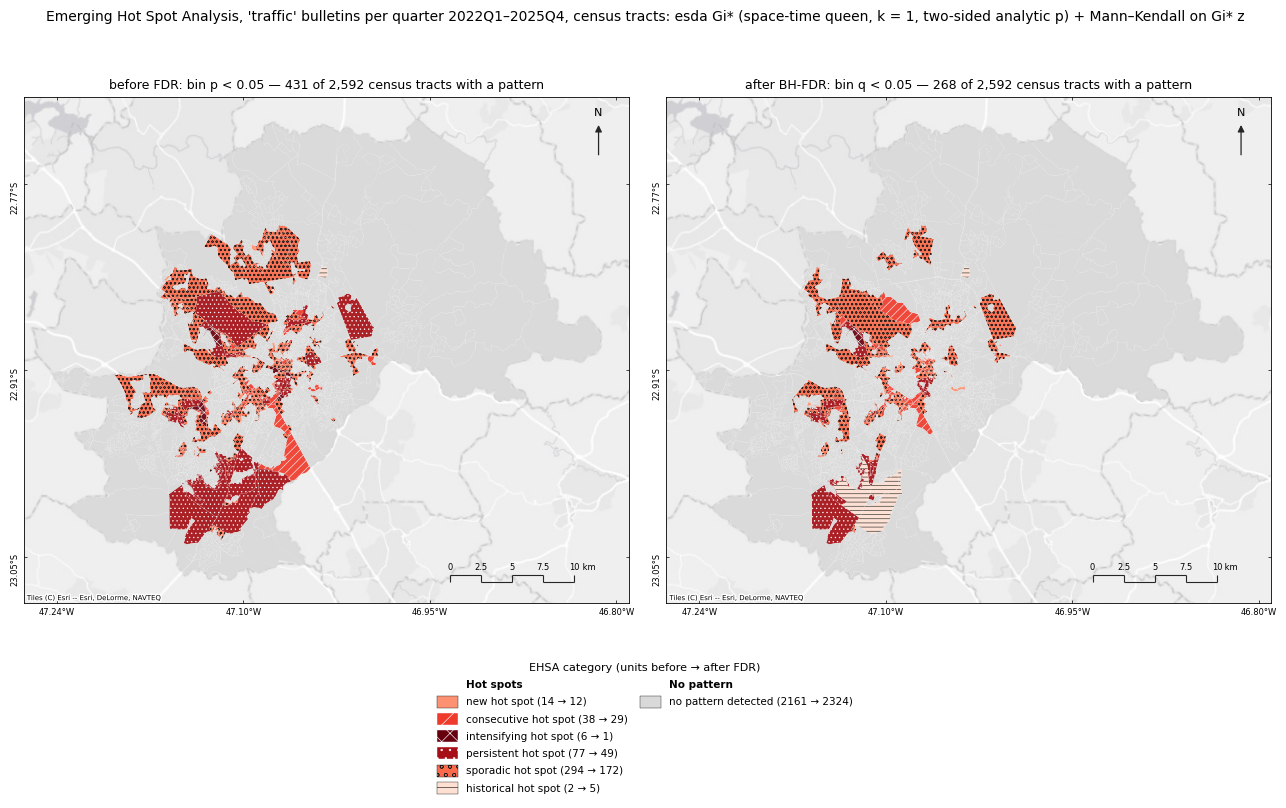

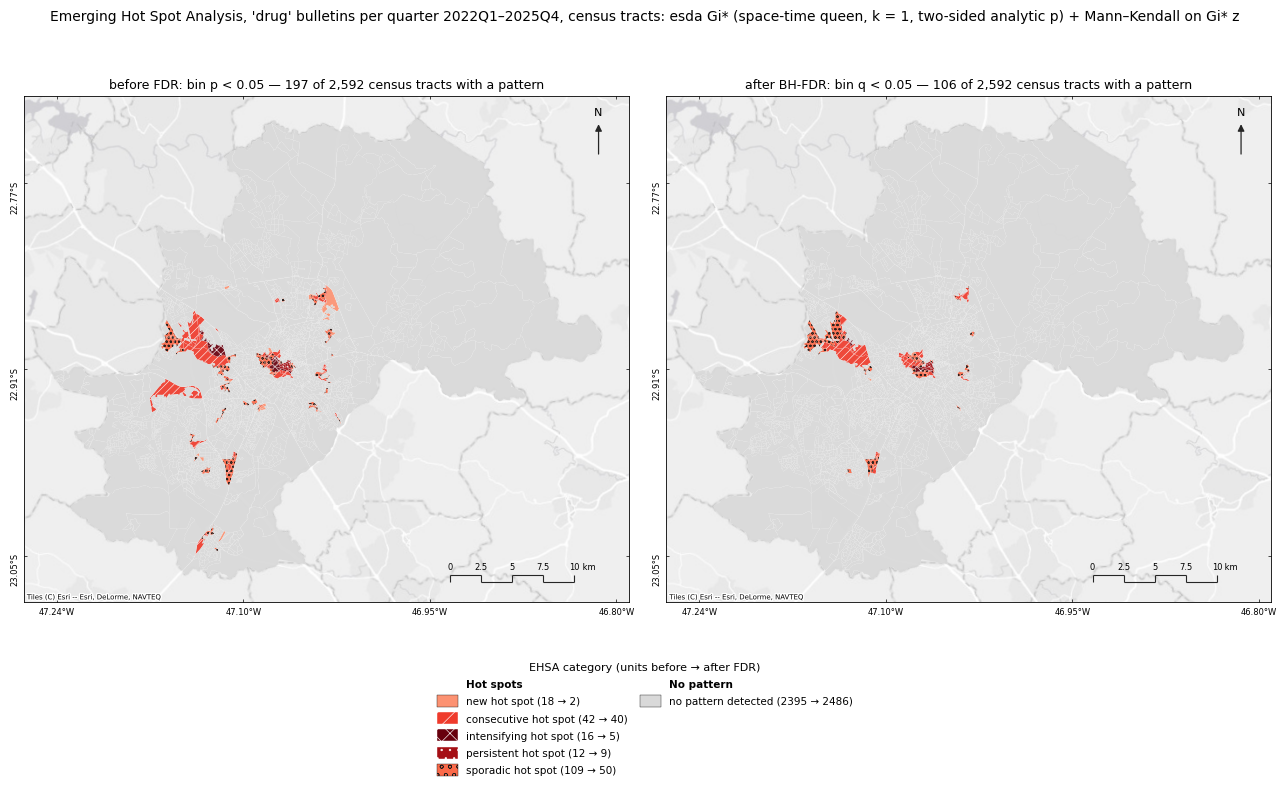

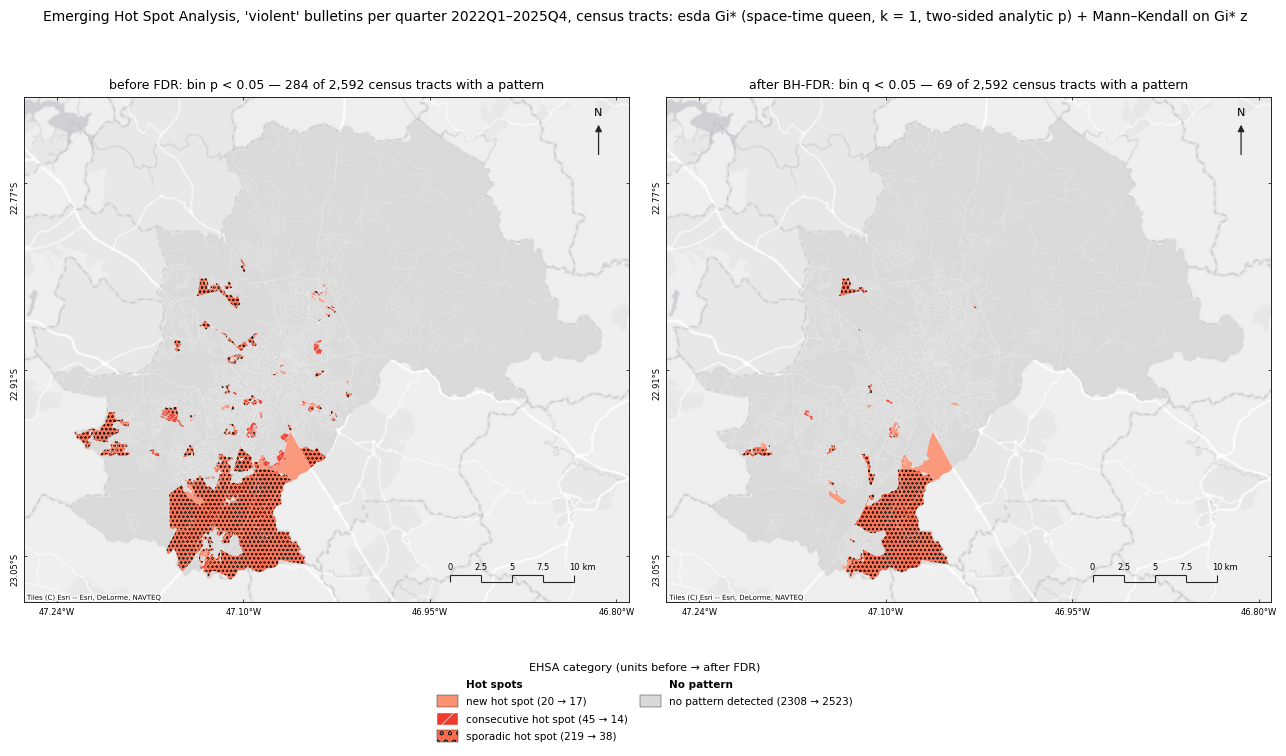

In [8]:
PATTERNS = ("new", "consecutive", "intensifying", "persistent", "diminishing", "sporadic", "oscillating", "historical")
HATCH = dict(zip(PATTERNS, ["", "//", "xx", "..", "\\\\", "oo", "++", "--"]))
REDS = dict(zip(PATTERNS, ["#fc9272", "#ef3b2c", "#67000d", "#a50f15", "#fcbba1", "#fb6a4a", "#cb181d", "#fee0d2"]))
BLUES = dict(zip(PATTERNS, ["#9ecae1", "#4292c6", "#08306b", "#08519c", "#c6dbef", "#6baed6", "#2171b5", "#deebf7"]))
STYLE = {f"{p} hot spot": (REDS[p], HATCH[p]) for p in PATTERNS}
STYLE |= {f"{p} cold spot": (BLUES[p], HATCH[p]) for p in PATTERNS}
STYLE["no pattern detected"] = ("#d9d9d9", "")
NAME = {"tract": "census tracts"}
COLS = {"category": "before FDR: bin p < 0.05", "category_fdr": "after BH-FDR: bin q < 0.05"}


def ehsa_before_after(s, g):
    df = labels[("Q", s, g)]
    units = data[s]["units"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 7))
    for ax, col in zip(axes, COLS):
        ms.plot_categories(ax, units, df[col], STYLE, hatch_repeat=2 if s == "tract" else 1,
                           linewidth=0.05 if s == "tract" else 0.3, edgecolor="white" if s == "tract" else "0.45")
        ms.decorate(ax, units.crs)
        n_sig = int((df[col] != "no pattern detected").sum())
        ax.set_title(f"{COLS[col]} — {n_sig} of {len(df):,} {NAME[s]} with a pattern", fontsize=9)
    before, after = df["category"].value_counts(), df["category_fdr"].value_counts()
    present = [c for c in CATEGORIES if before.get(c, 0) or after.get(c, 0) or c == "no pattern detected"]
    counts = {c: f"{before.get(c, 0)} → {after.get(c, 0)}" for c in present}
    groups = {"Hot spots": [(c, *STYLE[c]) for c in present if "hot" in c],
              "Cold spots": [(c, *STYLE[c]) for c in present if "cold" in c],
              "No pattern": [("no pattern detected", *STYLE["no pattern detected"])]}
    groups = {k: v for k, v in groups.items() if v}
    ms.category_legend(fig, groups, counts=counts, loc="upper center", bbox=(0.5, 0.06), fontsize=7.5,
                       title="EHSA category (units before → after FDR)")
    fig.suptitle(f"Emerging Hot Spot Analysis, '{g}' bulletins per quarter 2022Q1–2025Q4, {NAME[s]}: "
                 "esda Gi* (space-time queen, k = 1, two-sided analytic p) + Mann–Kendall on Gi* z", fontsize=10)
    fig.tight_layout(rect=(0, 0.06, 1, 0.97))
    fig.savefig(OUT / f"map_ehsa_{g}_{s}_before_after_fdr.png", dpi=300, bbox_inches="tight")
    plt.show(); plt.close(fig)


for g in GROUPS:
    for s in SUPPORTS:
        ehsa_before_after(s, g)

In [9]:
# counts table: category x (support, group, before / after FDR)
rows = {}
for g in GROUPS:
    for s in SUPPORTS:
        df = labels[("Q", s, g)]
        for col, when in (("category", "before FDR"), ("category_fdr", "after FDR")):
            rows[(g, s, when)] = df[col].value_counts()
before_after = pd.DataFrame(rows).reindex(CATEGORIES).fillna(0).astype(int)
before_after.columns.names = ["group", "support", "labels"]
before_after.to_csv(OUT / "before_after_fdr_counts.csv")
print("Units per EHSA category, quarterly, before FDR (bin p < 0.05) and after BH-FDR (bin q < 0.05)")
before_after

Units per EHSA category, quarterly, before FDR (bin p < 0.05) and after BH-FDR (bin q < 0.05)


group                         all             property           bodily_harm  \
support                     tract                tract                 tract   
labels                 before FDR after FDR before FDR after FDR  before FDR   
new hot spot                    3         2          4         1          58   
consecutive hot spot           18        12         14        12          43   
intensifying hot spot          37        24         29        17          10   
persistent hot spot           136        86        133        84          29   
diminishing hot spot           27        20         34        29           0   
sporadic hot spot              68        25         61        21         233   
oscillating hot spot            0         0          0         0           0   
historical hot spot             5         1         10         1           0   
new cold spot                   0         0          0         0           0   
consecutive cold spot           0         0          1         0           0   
intensifying cold spot          0         0          0         0           0   
persistent cold spot            0         0          1         0           0   
diminishing cold spot           0         0          0         0           0   
sporadic cold spot              6         0          3         0           0   
oscillating cold spot           0         0          0         0           0   
historical cold spot            0         0          0         0           0   
no pattern detected          2292      2422       2302      2427        2219   

group                               traffic                 drug            \
support                               tract                tract             
labels                 after FDR before FDR after FDR before FDR after FDR   
new hot spot                  22         14        12         18         2   
consecutive hot spot          17         38        29         42        40   
intensifying hot spot          6          6         1         16         5   
persistent hot spot           11         77        49         12         9   
diminishing hot spot           0          0         0          0         0   
sporadic hot spot             99        294       172        109        50   
oscillating hot spot           0          0         0          0         0   
historical hot spot            0          2         5          0         0   
new cold spot                  0          0         0          0         0   
consecutive cold spot          0          0         0          0         0   
intensifying cold spot         0          0         0          0         0   
persistent cold spot           0          0         0          0         0   
diminishing cold spot          0          0         0          0         0   
sporadic cold spot             0          0         0          0         0   
oscillating cold spot          0          0         0          0         0   
historical cold spot           0          0         0          0         0   
no pattern detected         2437       2161      2324       2395      2486   

group                     violent            
support                     tract            
labels                 before FDR after FDR  
new hot spot                   20        17  
consecutive hot spot           45        14  
intensifying hot spot           0         0  
persistent hot spot             0         0  
diminishing hot spot            0         0  
sporadic hot spot             219        38  
oscillating hot spot            0         0  
historical hot spot             0         0  
new cold spot                   0         0  
consecutive cold spot           0         0  
intensifying cold spot          0         0  
persistent cold spot            0         0  
diminishing cold spot           0         0  
sporadic cold spot              0         0  
oscillating cold spot           0         0  
historical

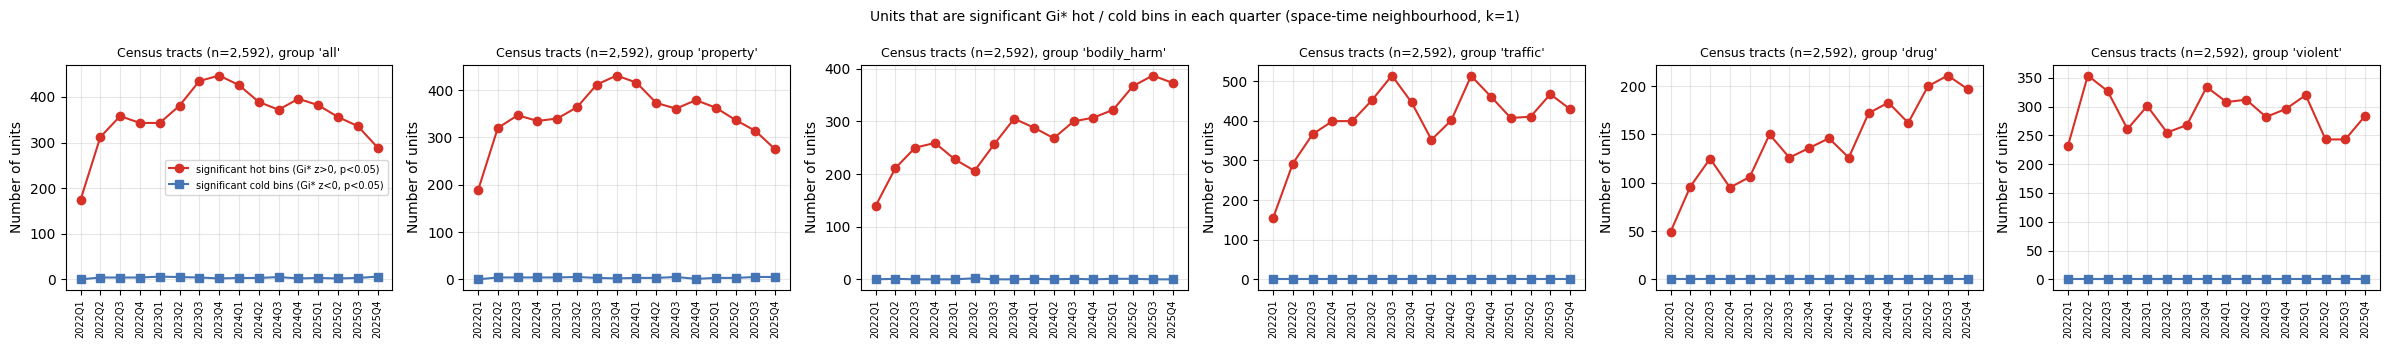

In [10]:
fig, axes = plt.subplots(len(SUPPORTS), len(GROUPS), figsize=(4 * len(GROUPS), 3.5 * len(SUPPORTS)), sharex=True, squeeze=False)
for row, s in enumerate(SUPPORTS):
    for col, g in enumerate(GROUPS):
        ax = axes[row, col]
        b = bins[[i for i, d in enumerate(bins) if d.support.iloc[0] == s and d.group.iloc[0] == g][0]]
        sig = b.p < ALPHA
        per = b.assign(hot=sig & (b.z > 0), cold=sig & (b.z < 0)).groupby("period")[["hot", "cold"]].sum()
        x = [f"{p.year}Q{p.quarter}" for p in per.index]
        ax.plot(x, per.hot, marker="o", color="#d73027", label="significant hot bins (Gi* z>0, p<0.05)")
        ax.plot(x, per.cold, marker="s", color="#4575b4", label="significant cold bins (Gi* z<0, p<0.05)")
        n = b.unit_id.nunique()
        ax.set_title(f"Census tracts (n={n:,}), group '{g}'", fontsize=9)
        ax.set_ylabel("Number of units")
        ax.tick_params(axis="x", rotation=90, labelsize=7)
        ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=7)
fig.suptitle("Units that are significant Gi* hot / cold bins in each quarter (space-time neighbourhood, k=1)", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "significant_bins_per_quarter.png", dpi=300, bbox_inches="tight")
plt.show()

### Why are there (almost) no cold spots?

A cold Gi* bin needs a neighbourhood sum *below* its expectation by ~2 standard deviations. With
skewed counts and many zeros (40 % of tract-quarters are 0) the lower tail of the analytic z is bounded:
an all-zero neighbourhood gives z = −E/√V, which for a 7-tract queen neighbourhood plus its lagged copy
is small in magnitude. The next cell prints the most negative attainable z (an all-zero neighbourhood)
next to the minimum observed z.

In [11]:
for s in SUPPORTS:
    for g in GROUPS:
        b = bins[[i for i, d in enumerate(bins) if d.support.iloc[0] == s and d.group.iloc[0] == g][0]]
        Y = tract_cube(g, "Q").to_numpy().T.reshape(-1).astype(float)
        wst = space_time_weights(data[s]["w"], 16)
        card = np.asarray(wst.sparse.sum(1)).ravel() + 1      # + self
        N = len(Y); mean = Y.mean(); var = Y.var()
        z0 = -(card / N) / np.sqrt(card * (N - card) / (N - 1) / N**2 * var / mean**2)
        print(f"{s:5s} {g:9s}: z of an all-zero neighbourhood: median {np.median(z0):6.2f}, "
              f"most negative {z0.min():6.2f}; observed min z {b.z.min():6.2f}; "
              f"bins with z <= -1.96: {(b.z <= -1.96).sum()}")

tract all      : z of an all-zero neighbourhood: median  -1.49, most negative  -3.80; observed min z  -2.44; bins with z <= -1.96: 56


tract property : z of an all-zero neighbourhood: median  -1.40, most negative  -3.57; observed min z  -2.42; bins with z <= -1.96: 54


tract bodily_harm: z of an all-zero neighbourhood: median  -1.11, most negative  -2.83; observed min z  -2.24; bins with z <= -1.96: 7


tract traffic  : z of an all-zero neighbourhood: median  -1.01, most negative  -2.57; observed min z  -1.93; bins with z <= -1.96: 0


tract drug     : z of an all-zero neighbourhood: median  -0.55, most negative  -1.39; observed min z  -1.30; bins with z <= -1.96: 0


tract violent  : z of an all-zero neighbourhood: median  -0.37, most negative  -0.95; observed min z  -0.95; bins with z <= -1.96: 0


## 6. Outputs

In [12]:
for (f, s, g), df in labels.items():
    suffix = "quarterly" if f == "Q" else "monthly"
    df.insert(0, "group", g); df.insert(0, "support", s)
    df.to_csv(OUT / f"ehsa_{s}_{g}_{suffix}.csv", index=False)
pd.concat(bins).to_parquet(OUT / "gi_bins_quarterly.parquet", index=False)
primary_counts.to_csv(OUT / "category_counts.csv")
runtimes.to_csv(OUT / "runtimes.csv", index=False)
print(sorted(p.name for p in OUT.iterdir()))

['before_after_fdr_counts.csv', 'category_counts.csv', 'ehsa_tract_all_monthly.csv', 'ehsa_tract_all_quarterly.csv', 'ehsa_tract_bodily_harm_monthly.csv', 'ehsa_tract_bodily_harm_quarterly.csv', 'ehsa_tract_drug_monthly.csv', 'ehsa_tract_drug_quarterly.csv', 'ehsa_tract_property_monthly.csv', 'ehsa_tract_property_quarterly.csv', 'ehsa_tract_traffic_monthly.csv', 'ehsa_tract_traffic_quarterly.csv', 'ehsa_tract_violent_monthly.csv', 'ehsa_tract_violent_quarterly.csv', 'gi_bins_quarterly.parquet', 'map_ehsa_all_tract_before_after_fdr.png', 'map_ehsa_bodily_harm_tract_before_after_fdr.png', 'map_ehsa_drug_tract_before_after_fdr.png', 'map_ehsa_property_tract_before_after_fdr.png', 'map_ehsa_traffic_tract_before_after_fdr.png', 'map_ehsa_violent_tract_before_after_fdr.png', 'runtimes.csv', 'significant_bins_per_quarter.png', 'variants_summary.csv']


## Findings

In [13]:
def hot_cold(df, col="category"):
    c = df[col]
    return int(c.str.contains("hot").sum()), int(c.str.contains("cold").sum())

for s in SUPPORTS:
    for g in GROUPS:
        df = labels[("Q", s, g)]
        h, c = hot_cold(df); hf, cf = hot_cold(df, "category_fdr"); hs, cs = hot_cold(df, "category_spatial")
        top = df["category"][df["category"] != "no pattern detected"].value_counts().head(3)
        print(f"{s}/{g}: {h} hot-spot and {c} cold-spot units of {len(df)} "
              f"(BH: {hf} hot / {cf} cold; purely spatial: {hs} hot / {cs} cold). "
              f"Largest categories: " + ", ".join(f"{k} {v}" for k, v in top.items()))
print("total runtime of all configurations:", runtimes.seconds.sum().round(1), "s")

tract/all: 294 hot-spot and 6 cold-spot units of 2592 (BH: 170 hot / 0 cold; purely spatial: 266 hot / 0 cold). Largest categories: persistent hot spot 136, sporadic hot spot 68, intensifying hot spot 37
tract/property: 285 hot-spot and 5 cold-spot units of 2592 (BH: 165 hot / 0 cold; purely spatial: 280 hot / 0 cold). Largest categories: persistent hot spot 133, sporadic hot spot 61, diminishing hot spot 34
tract/bodily_harm: 373 hot-spot and 0 cold-spot units of 2592 (BH: 155 hot / 0 cold; purely spatial: 174 hot / 0 cold). Largest categories: sporadic hot spot 233, new hot spot 58, consecutive hot spot 43
tract/traffic: 431 hot-spot and 0 cold-spot units of 2592 (BH: 268 hot / 0 cold; purely spatial: 339 hot / 0 cold). Largest categories: sporadic hot spot 294, persistent hot spot 77, consecutive hot spot 38
tract/drug: 197 hot-spot and 0 cold-spot units of 2592 (BH: 106 hot / 0 cold; purely spatial: 119 hot / 0 cold). Largest categories: sporadic hot spot 109, consecutive hot spot 

_The interpretation paragraph below was written after running the notebook; the printed lines above are
the authoritative numbers._

- **Hot spots dominate; cold spots are almost absent.** Under the primary settings 294 of 2,592 tracts
  (`all`) and 285 (`property`) get a hot-spot category, against 6 and 5 cold-spot tracts. *Persistent hot
  spot* is the largest category (136 tracts for `all`), followed by *sporadic* (68) and *intensifying* (37). The hot spots form the same central and
  north-western clusters for both groups (property is 84 % of all bulletins, so the two groups are not
  independent evidence).
- **Why so few cold spots:** an all-zero space-time neighbourhood reaches only z ≈ −1.5 (median over
  tract bins), so the analytic Gi* rarely crosses −1.96 on these skewed, zero-heavy counts (56 tract bins of
  41,472 for `all`). The few cold labels sit in large peripheral tracts. Do not read the absence of cold spots as an absence of low-crime areas.
- **Sensitivity.** BH over all bins removes about 40 % of the hot-spot tracts (294 → 170) and every cold
  spot; α = 0.01 gives 205. The purely spatial neighbourhood (no temporal neighbours, not Esri's) keeps 266
  hot-spot tracts and agrees with the primary label on 93 % of tracts. Hamed–Rao changes 1 % of the tract
  labels (its variance correction returned NaN p for 45 tracts, treated as no trend). Monthly bins give
  257 hot-spot tracts and 93 % agreement with the quarterly labels.
- **Before / after FDR (section 5).** `all`: 294 hot-spot and 6 cold-spot tracts before FDR → 170 and 0
  after BH. BH mostly removes *sporadic* (68 → 25) and *persistent* (136 → 86)
  tracts at the edges of the clusters; the central and north-western clusters and the large south-western tracts stay.
  Maps: `map_ehsa_{group}_tract_before_after_fdr.png`; table: `before_after_fdr_counts.csv`.
- **Label precision.** The sub-category of a hot spot hinges on single bins (15 of 16 for the 90 % rule)
  and on the trend test; the hot / not-hot family is the more stable result.